# Evaluating the event-detection checkpoints

This notebook walks through, step by step, how to

1. load a trained checkpoint,
2. load the LoL-V2T validation and test data,
3. choose the confidence threshold on the validation set,
4. evaluate the model on the **test set** (loss, accuracy, precision, recall, F1, AUROC),
5. draw its confusion matrix,
6. compare several checkpoints in one table and one grid of confusion matrices,
7. look at the precision/recall trade-off of the best model.

**Requirements.** The repository environment (`make install`, or `make install-gpu` for CUDA) and the cached features for the val and test splits. The first time, build the cache once from the downloaded dataset:

```bash
python -m detection.gpu_data --splits val test
```

**Labels.** Each clip is a sequence of feature steps (one step is about 0.217 s). A step is labelled `kill`, `objective` or `teamfight` if a commentary sentence with the matching keywords starts `label_offset_s` seconds earlier (a 3 s window); everything else is `background`. Models were trained with different label offsets, so each model is scored against *its own* labels. Only compare numbers within the same offset.

**Protocol.** The confidence threshold (`min_conf`) is picked on the validation set only. The test set is used for reporting.

## 0. Setup

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml

warnings.filterwarnings("ignore")

# run from the repository root regardless of where Jupyter was started
ROOT = Path.cwd().parent if Path.cwd().name == "visualisation" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from common.device import torch_device  # noqa: E402
from common.lolv2t import CLASSES  # noqa: E402
from detection.gpu_data import EvalSet, GpuSplit  # noqa: E402
from detection.model import build_model  # noqa: E402
from detection.plot_confusion import draw  # noqa: E402
from detection.score_fast import show_matrix  # noqa: E402
from detection.weight_search import evaluate, rank_metrics  # noqa: E402

device = torch_device("auto")
OUT = ROOT / "visualisation" / "output"
OUT.mkdir(exist_ok=True)
print("repository:", ROOT)
print("device    :", device)
print("classes   :", CLASSES)

# detection.plot_confusion selects a file-only backend; show figures inline in the notebook
%matplotlib inline

repository: /media/1T_ssd_ext4/workspace/video_event_detection
device    : cuda
classes   : ['background', 'kill', 'objective', 'teamfight']


## 1. What checkpoints are available

`checkpoints/manifest.json` lists every checkpoint with its architecture, config, label offset and a short description.

In [2]:
manifest = pd.DataFrame(json.loads((ROOT / "checkpoints" / "manifest.json").read_text()))
manifest = manifest.set_index("name")
manifest[["arch", "parameters", "label_offset_s", "bg_keep", "description"]]

,arch,parameters,label_offset_s,bg_keep,description
name,,,,,
detector,vunet,1645764,0.0,1.0,"Variational U-Net (CE + reconstruction + KL), ..."
detector_unet,unet,1149252,0.0,1.0,"Plain U-Net, first trainer, epoch 30 of 100"
detector_unet_wsp,unet,1149252,0.0,1.0,detector_unet after gradient-free weight-space...
base_c,unet,1149252,0.0,1.0,"U-Net, GPU trainer, no extra regularisation"
reg2_c,unet,1149252,0.0,1.0,"U-Net, dropout 0.2, input dropout 0.3, noise 0..."
reg3_c,unet,353444,0.0,1.0,"U-Net hidden 32, stronger regularisation"
reg4_c,unet,121428,0.0,1.0,"U-Net hidden 16, input dropout 0.5, wd 0.05"
reg5_c,unet,1149252,0.0,1.0,"U-Net, input dropout 0.7"
wt075,unet,121428,0.0,1.0,"reg4 U-Net, class weight power 0.75"


## 2. Load one checkpoint

A checkpoint is a plain dictionary of tensors plus the information needed to rebuild the network: `arch`, `model_kwargs`, `in_dim`, the input feature mean and std (stored inside `state_dict`), and the aggregator settings used for event extraction. Loading with `weights_only=True` is safe because nothing but tensors and simple values is stored.

In [3]:
def load_model(name: str):
    ckpt = torch.load(ROOT / "checkpoints" / f"{name}.pt", map_location="cpu", weights_only=True)
    model = build_model(ckpt["arch"], ckpt["in_dim"], **ckpt["model_kwargs"])
    model.load_state_dict(ckpt["state_dict"])
    return model.to(device).eval(), ckpt


model, ckpt = load_model("gru_reg2")
n_params = sum(p.numel() for p in model.parameters())
print("architecture :", ckpt["arch"], ckpt["model_kwargs"])
print("input dim    :", ckpt["in_dim"], "| classes:", ckpt["classes"])
print("parameters   :", f"{n_params:,}")
print("stored aggregator:", ckpt["aggregator"])

architecture : bigru {'hidden': 64, 'layers': 2, 'dropout': 0.4, 'in_dropout': 0.6, 'noise_std': 0.5}
input dim    : 4096 | classes: ['background', 'kill', 'objective', 'teamfight']
parameters   : 387,140
stored aggregator: {'min_run': 2, 'min_conf': 0.2}


## 3. Load the data

`GpuSplit` reads the cached fp16 features of a split and builds the per-step labels for a given `label_offset_s`. `EvalSet` groups clips of equal length (so no padding is needed) and puts them on the device. We build the validation and test sets once per label offset and reuse them.

In [4]:
base_cfg = yaml.safe_load((ROOT / "detection" / "configs" / "default.yaml").read_text())
DATA_ROOT = Path(base_cfg["root"])
TOL = base_cfg["tolerance_s"]  # an event counts as found if it is within this many seconds
_sets = {}


def get_sets(offset: float):
    """Validation and test EvalSets whose labels use the given offset (cached)."""
    if offset not in _sets:
        cfg = {**base_cfg, "label_offset_s": offset}
        out = {}
        for split in ("val", "test"):
            gs = GpuSplit(DATA_ROOT, split, cfg, device)
            out[split] = EvalSet(gs, range(len(gs)))
        _sets[offset] = out
    return _sets[offset]


offset = float(manifest.loc["gru_reg2", "label_offset_s"])
sets = get_sets(offset)
print(f"label offset {offset:+g} s | val clips {sets['val'].n} | test clips {sets['test'].n}")

label offset +6 s | val clips 851 | test clips 1895


## 4. Choose the confidence threshold on the validation set

Events are extracted from the per-step class probabilities: a step is background unless the top class has probability above `min_conf`, and a run of the same class that lasts `min_run` steps becomes one event. We pick `min_conf` from a small grid by the mean event F1 **on the validation set**.

In [5]:
CONF_GRID = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]


def tune_conf(model, val_set, aggregator):
    scores = {c: evaluate(model, val_set, {**aggregator, "min_conf": c}, TOL)["mean_event_f1"] for c in CONF_GRID}
    return max(scores, key=scores.get), scores


best_conf, val_scores = tune_conf(model, sets["val"], ckpt["aggregator"])
pd.Series(val_scores, name="val event F1").rename_axis("min_conf").to_frame().T.round(3)

min_conf,0.2,0.3,0.4,0.5,0.6,0.7
val event F1,0.142,0.138,0.082,0.005,0.0,0.0


In [6]:
print("chosen min_conf (validation):", best_conf)

chosen min_conf (validation): 0.2


## 5. Evaluate on the test set

`evaluate` returns the loss (cross-entropy over all steps), step-level accuracy, precision, recall and F1 (macro over the four classes) and event-level precision, recall and F1. `rank_metrics` adds the threshold-free one-vs-rest **AUROC** and average precision for each event class; chance AUROC is 0.5.

In [7]:
agg = {**ckpt["aggregator"], "min_conf": best_conf}
test = evaluate(model, sets["test"], agg, TOL)
test["rank"] = rank_metrics(model, sets["test"])
step = test["step"]

print(f"loss (cross-entropy) : {test['ce']:.3f}")
print(f"step accuracy        : {step['accuracy']:.3f}")
print(f"step macro P / R / F1: {step['macro_precision']:.3f} / {step['macro_recall']:.3f} / {step['macro_f1']:.3f}")
print(f"event P / R / F1     : {test['mean_event_precision']:.3f} / {test['mean_event_recall']:.3f} / {test['mean_event_f1']:.3f}")
print(f"mean AUROC           : {test['rank']['mean_auroc']:.3f}")

loss (cross-entropy) : 0.962
step accuracy        : 0.606
step macro P / R / F1: 0.292 / 0.369 / 0.279
event P / R / F1     : 0.126 / 0.164 / 0.138
mean AUROC           : 0.693


In [8]:
per_class = pd.DataFrame(step["per_class"]).T.rename(columns=str.title)
per_class["Support (steps)"] = per_class["Support"].astype(int)
per_class = per_class.drop(columns="Support")
per_class["AUROC"] = pd.Series(test["rank"]["auroc"])
per_class["AP"] = pd.Series(test["rank"]["ap"])
per_class["Base rate"] = pd.Series(test["rank"]["base_rate"])
per_class.round(3)

,Precision,Recall,F1,Support (steps),AUROC,AP,Base rate
background,0.935,0.641,0.761,211749,NaN,NaN,NaN
kill,0.084,0.241,0.125,7815,0.681,0.066,0.033
objective,0.076,0.432,0.130,9464,0.710,0.079,0.040
teamfight,0.074,0.160,0.101,6787,0.687,0.054,0.029


## 6. Confusion matrix of this model

Rows are the true class, columns the predicted class. The colour is the row-normalised share, i.e. the recall of each true class, and each cell also shows the raw number of steps. These are the step-level predictions (arg-max class of every step).

    true \ pred   backgroun       kill  objective  teamfight
    background       135821      18492      45234      12202
    kill               3199       1883       2025        708
    objective          3704        981       4089        690
    teamfight          2604        930       2166       1087


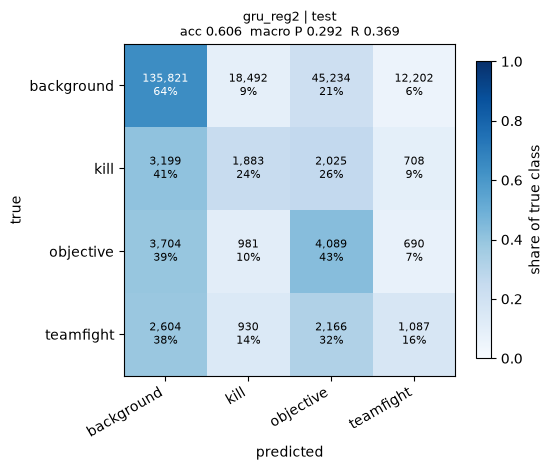

In [9]:
print(show_matrix(step))
fig, ax = plt.subplots(figsize=(5.6, 4.9))
im = draw(ax, step, "gru_reg2 | test")
fig.colorbar(im, ax=ax, shrink=0.8, label="share of true class")
fig.tight_layout()
plt.show()

## 7. Compare several checkpoints

The next cell loads each checkpoint, tunes its threshold on validation, scores it on the test set and collects everything in one table. The default list mixes label offsets 0 and +6 s; scores are only comparable *within* an offset. Edit `COMPARE` to include any checkpoint listed in section 1.

In [10]:
COMPARE = ["detector_unet", "reg4_c", "wt075", "rs0_control", "ctx_bigru", "gru_reg2", "gru_reg4"]

results = {}
for name in COMPARE:
    m, ck = load_model(name)
    off = float(manifest.loc[name, "label_offset_s"])
    s = get_sets(off)
    conf, _ = tune_conf(m, s["val"], ck["aggregator"])
    a = {**ck["aggregator"], "min_conf": conf}
    t = evaluate(m, s["test"], a, TOL)
    t["rank"] = rank_metrics(m, s["test"])
    results[name] = {"model": m, "conf": conf, "offset": off, "test": t}
    print(f"{name:18s} min_conf {conf:.1f}  AUROC {t['rank']['mean_auroc']:.3f}")

detector_unet      min_conf 0.4  AUROC 0.563


reg4_c             min_conf 0.2  AUROC 0.613


wt075              min_conf 0.3  AUROC 0.609


rs0_control        min_conf 0.2  AUROC 0.657


ctx_bigru          min_conf 0.2  AUROC 0.691


gru_reg2           min_conf 0.2  AUROC 0.693


gru_reg4           min_conf 0.2  AUROC 0.686


In [11]:
rows = []
for name, r in results.items():
    t, st = r["test"], r["test"]["step"]
    rows.append({
        "model": name,
        "arch": manifest.loc[name, "arch"],
        "params": int(manifest.loc[name, "parameters"]),
        "label offset (s)": r["offset"],
        "min_conf": r["conf"],
        "loss": t["ce"],
        "accuracy": st["accuracy"],
        "AUROC": t["rank"]["mean_auroc"],
        "step macro P": st["macro_precision"],
        "step macro R": st["macro_recall"],
        "step macro F1": st["macro_f1"],
        "event P": t["mean_event_precision"],
        "event R": t["mean_event_recall"],
        "event F1": t["mean_event_f1"],
    })
table = pd.DataFrame(rows).set_index("model").sort_values(["label offset (s)", "AUROC"], ascending=[True, False])
table.to_csv(OUT / "test_comparison.csv")
table.round(3)

,arch,params,label offset (s),min_conf,loss,accuracy,AUROC,step macro P,step macro R,step macro F1,event P,event R,event F1
model,,,,,,,,,,,,,
reg4_c,unet,121428,0.0,0.2,0.758,0.820,0.613,0.295,0.279,0.281,0.137,0.133,0.129
wt075,unet,121428,0.0,0.3,1.004,0.695,0.609,0.282,0.312,0.284,0.111,0.278,0.158
detector_unet,unet,1149252,0.0,0.4,0.863,0.701,0.563,0.269,0.279,0.263,0.099,0.250,0.133
gru_reg2,bigru,387140,6.0,0.2,0.962,0.606,0.693,0.292,0.369,0.279,0.126,0.164,0.138
ctx_bigru,bigru,387140,6.0,0.2,0.946,0.743,0.691,0.296,0.334,0.301,0.132,0.142,0.136
gru_reg4,bigru,387140,6.0,0.2,1.124,0.432,0.686,0.288,0.384,0.231,0.110,0.200,0.140
rs0_control,unet,121428,6.0,0.2,1.009,0.772,0.657,0.286,0.300,0.285,0.109,0.181,0.133


In [12]:
# highlight the best value of every metric within each label offset
def highlight(df):
    cols = ["accuracy", "AUROC", "step macro P", "step macro R", "step macro F1", "event P", "event R", "event F1"]
    styled = df.style.format({c: "{:.3f}" for c in cols + ["loss"]})
    for _, group in df.groupby("label offset (s)"):
        for c in cols:
            styled = styled.highlight_max(subset=pd.IndexSlice[group.index, c], color="#cfe8cf")
        styled = styled.highlight_min(subset=pd.IndexSlice[group.index, "loss"], color="#cfe8cf")
    return styled


highlight(table)

,arch,params,label offset (s),min_conf,loss,accuracy,AUROC,step macro P,step macro R,step macro F1,event P,event R,event F1
model,,,,,,,,,,,,,
reg4_c,unet,121428,0.000000,0.200000,0.758,0.820,0.613,0.295,0.279,0.281,0.137,0.133,0.129
wt075,unet,121428,0.000000,0.300000,1.004,0.695,0.609,0.282,0.312,0.284,0.111,0.278,0.158
detector_unet,unet,1149252,0.000000,0.400000,0.863,0.701,0.563,0.269,0.279,0.263,0.099,0.250,0.133
gru_reg2,bigru,387140,6.000000,0.200000,0.962,0.606,0.693,0.292,0.369,0.279,0.126,0.164,0.138
ctx_bigru,bigru,387140,6.000000,0.200000,0.946,0.743,0.691,0.296,0.334,0.301,0.132,0.142,0.136
gru_reg4,bigru,387140,6.000000,0.200000,1.124,0.432,0.686,0.288,0.384,0.231,0.110,0.200,0.140
rs0_control,unet,121428,6.000000,0.200000,1.009,0.772,0.657,0.286,0.300,0.285,0.109,0.181,0.133


## 8. Confusion matrices of all compared models

One heatmap per model on the test set, row-normalised, with the raw step counts in the cells.

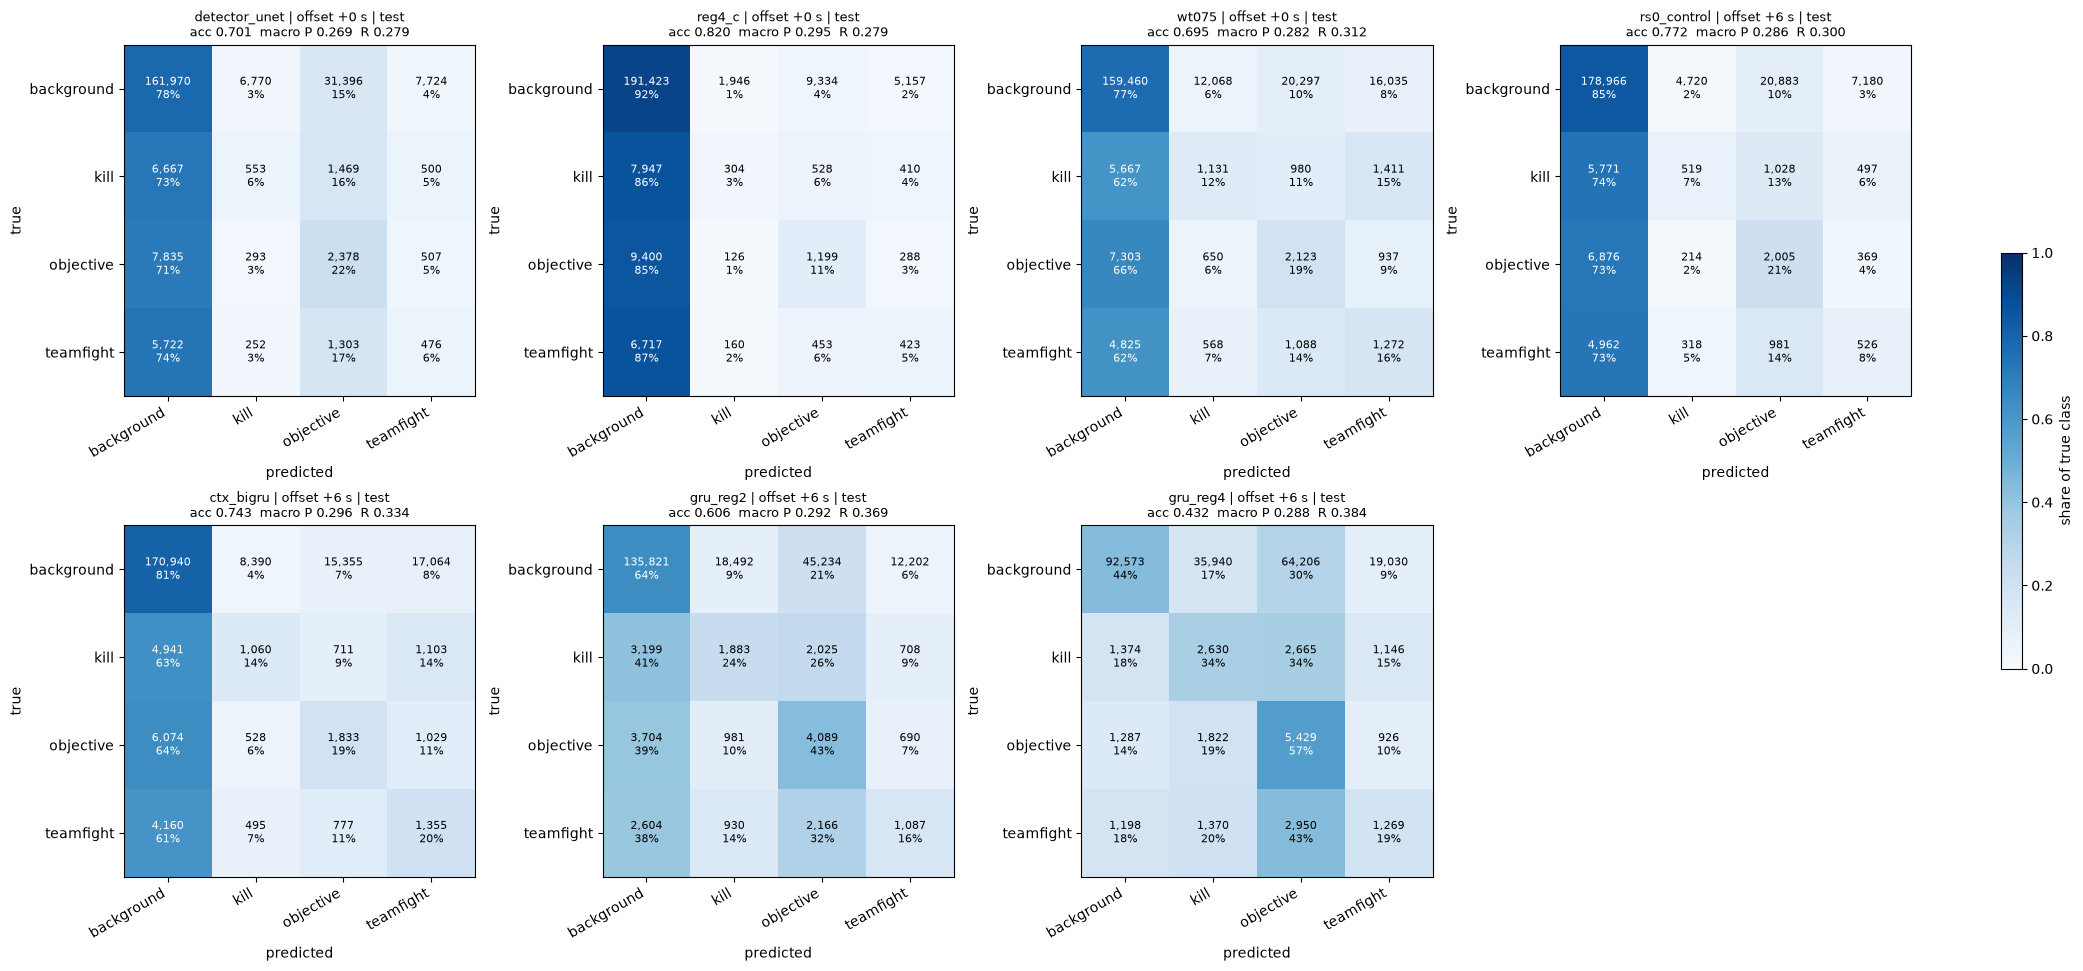

In [13]:
n = len(results)
cols = 4
rows_n = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(5.2 * cols, 4.8 * rows_n), layout="constrained")
axes = np.atleast_1d(axes).ravel()
for ax, (name, r) in zip(axes, results.items(), strict=False):
    im = draw(ax, r["test"]["step"], f"{name} | offset {r['offset']:+g} s | test")
for ax in axes[n:]:
    ax.axis("off")
fig.colorbar(im, ax=axes.tolist(), shrink=0.5, label="share of true class")
fig.savefig(OUT / "confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

In [14]:
# the same matrices as raw counts, one table per model
for name, r in results.items():
    cm = pd.DataFrame(r["test"]["step"]["confusion_matrix"], index=CLASSES, columns=CLASSES)
    cm.index.name = f"{name} (true \\ pred)"
    display(cm)

,background,kill,objective,teamfight
detector_unet (true \ pred),,,,
background,161970,6770,31396,7724
kill,6667,553,1469,500
objective,7835,293,2378,507
teamfight,5722,252,1303,476


,background,kill,objective,teamfight
reg4_c (true \ pred),,,,
background,191423,1946,9334,5157
kill,7947,304,528,410
objective,9400,126,1199,288
teamfight,6717,160,453,423


,background,kill,objective,teamfight
wt075 (true \ pred),,,,
background,159460,12068,20297,16035
kill,5667,1131,980,1411
objective,7303,650,2123,937
teamfight,4825,568,1088,1272


,background,kill,objective,teamfight
rs0_control (true \ pred),,,,
background,178966,4720,20883,7180
kill,5771,519,1028,497
objective,6876,214,2005,369
teamfight,4962,318,981,526


,background,kill,objective,teamfight
ctx_bigru (true \ pred),,,,
background,170940,8390,15355,17064
kill,4941,1060,711,1103
objective,6074,528,1833,1029
teamfight,4160,495,777,1355


,background,kill,objective,teamfight
gru_reg2 (true \ pred),,,,
background,135821,18492,45234,12202
kill,3199,1883,2025,708
objective,3704,981,4089,690
teamfight,2604,930,2166,1087


,background,kill,objective,teamfight
gru_reg4 (true \ pred),,,,
background,92573,35940,64206,19030
kill,1374,2630,2665,1146
objective,1287,1822,5429,926
teamfight,1198,1370,2950,1269


## 9. Precision/recall trade-off of one model

The class weights or background downsampling used in training only move a model along a trade-off between predicting background and predicting events; they do not change how well the classes are separated (that is what AUROC measures). To see the trade-off, multiply the background probability by a factor before taking the arg-max: a larger factor predicts more background, a smaller one finds more events.

,background recall,kill recall,objective recall,teamfight recall,mean event recall,mean event precision
background factor,,,,,,
0.25,0.214,0.462,0.650,0.173,0.428,0.059
0.50,0.315,0.425,0.632,0.172,0.410,0.063
0.75,0.482,0.331,0.562,0.168,0.354,0.070
1.00,0.641,0.241,0.432,0.160,0.278,0.078
1.50,0.859,0.091,0.203,0.111,0.135,0.095
2.00,0.956,0.019,0.074,0.052,0.049,0.117
3.00,0.998,0.000,0.002,0.001,0.001,0.050
5.00,1.000,0.000,0.000,0.000,0.000,0.000


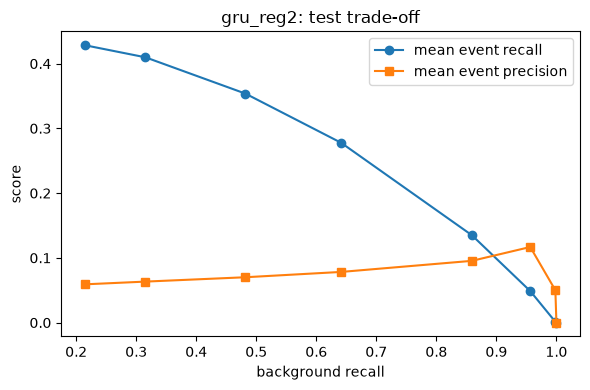

In [15]:
def step_probs(model, eval_set):
    P, Y = [], []
    with torch.no_grad():
        for _, x, y in eval_set.groups:
            out = model(x.float())
            logits = out["logits"] if isinstance(out, dict) else out
            P.append(torch.softmax(logits, 1).permute(0, 2, 1).reshape(-1, len(CLASSES)))
            Y.append(y.reshape(-1))
    return torch.cat(P), torch.cat(Y)


def recall_precision(P, Y, background_factor):
    q = P.clone()
    q[:, 0] *= background_factor
    cm = torch.bincount(Y * 4 + q.argmax(1), minlength=16).view(4, 4).float()
    return (cm.diag() / cm.sum(1)).cpu().numpy(), (cm.diag() / cm.sum(0).clamp(min=1)).cpu().numpy()


name = "gru_reg2"
P, Y = step_probs(results[name]["model"], get_sets(results[name]["offset"])["test"])
rows = []
for f in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5]:
    rec, prec = recall_precision(P, Y, f)
    rows.append({"background factor": f, "background recall": rec[0], "kill recall": rec[1],
                 "objective recall": rec[2], "teamfight recall": rec[3],
                 "mean event recall": rec[1:].mean(), "mean event precision": prec[1:].mean()})
tradeoff = pd.DataFrame(rows).set_index("background factor")
display(tradeoff.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(tradeoff["background recall"], tradeoff["mean event recall"], "o-", label="mean event recall")
ax.plot(tradeoff["background recall"], tradeoff["mean event precision"], "s-", label="mean event precision")
ax.set_xlabel("background recall")
ax.set_ylabel("score")
ax.set_title(f"{name}: test trade-off")
ax.legend()
fig.tight_layout()
plt.show()

## Notes

* **Accuracy is misleading** here: about 90% of steps are background, so a model that mostly predicts background has high accuracy and poor event recall. Look at macro recall, F1 and AUROC.
* **AUROC is the threshold-free measure** of how well a class is separated. It does not depend on class weights, downsampling or the confidence threshold. The models here reach about 0.55 to 0.69 on test.
* **Labels are noisy:** they come from commentary keywords, which lag or lead the action. That limits every score, on training clips as well as on test clips.
* **Threshold and checkpoint choices were made on validation data**, not on the test set.